# Langkah 10 Anggota A — Pembanding Filter Method (Mutual Information, top-k)

**Tugas (Rencana Kerja, Panduan Anggota A langkah 10, Minggu 11):** hitung *mutual information* (MI) antara setiap fitur dan label emosi **hanya di data train**, ambil **top-k dengan k = ukuran subset SA**, lalu serahkan daftar indeksnya ke Anggota B untuk dievaluasi dengan protokol yang sama (tabel ketergantungan no. 4 dan 5).

**Apa itu mutual information?** MI mengukur seberapa banyak satu fitur, *sendirian*, memberi tahu tentang label emosi. Nilainya 0 jika fitur tidak berhubungan dengan emosi; makin besar, makin informatif. *Filter method* memilih fitur dengan MI tertinggi tanpa melatih model, sehingga cepat. Kelemahannya, setiap fitur dinilai sendiri-sendiri, jadi fitur yang saling kembar bisa terpilih bersamaan dan kombinasi yang saling melengkapi tidak diperhitungkan.

**Kenapa perlu pembanding ini?** Untuk menjawab pertanyaan inti proyek: apakah SA, yang menilai **kombinasi** fitur, lebih baik daripada sekadar mengambil fitur-fitur terbaik secara **individual**?

**Parameter yang dipakai (dari hasil Anggota B)**

| Parameter | Nilai | Sumber |
| --- | --- | --- |
| Versi tabel fitur | `peak` | Terpilih di baseline B (SVM val macro F1 0,5165 vs 0,4846 untuk `none`) |
| k | 52 | SA utama B (P0, seed 42); juga median 3 seed SA di P0 (52, 52, 54) |
| Data | Train split utama (aktor 1–16, 960 file) | Rencana Kerja: MI hanya di train |
| Estimator | `mutual_info_classif`, `n_neighbors = 3`, rata-rata 10 seed | Estimator k-NN berbasis acak; rata-rata 10 seed membuat peringkat stabil |

**Input dan output**

| Jenis | Lokasi (di `MyDrive/project07/`) | Keterangan |
| --- | --- | --- |
| Input | `data/features/features_peak.csv`, `feature_names.csv` | Langkah 5 |
| Input | `data/splits.json`, `src/data_splits.py` | Langkah 7 |
| Input | `data/analysis/corr_clusters_peak.csv`, `src/redundancy.py` | Langkah 11 |
| Input (opsional) | `progres_anggota_b/results/sa_main_results.json` | Subset SA-52 milik B, untuk perbandingan |
| Output | `data/analysis/mi_scores_peak.csv` | Skor MI 90 fitur, peringkat, kelompok redundan |
| Output | `data/analysis/mi_topk_peak.json` | **Daftar 52 indeks untuk B**, format sesuai kontrak `subsets.json` |
| Output | `figures/mutual_info/` | 2 grafik + `mi_summary.txt` |
| Output | `docs/README_langkah10_mutual_information.md` | Dokumentasi standar |

**Aturan data:** data test (aktor 21–24) tidak disentuh. Sel 5 berisi **pratinjau** evaluasi di validation dengan protokol B; angka resmi tetap dari evaluasi B dan fungsi `evaluate()` milik C.

**Perkiraan waktu:** 1–3 menit. **Cara pakai:** jalankan sel berurutan dengan `Shift + Enter`.

## Sel 1 — Persiapan dan cek prasyarat

In [1]:
import os
import sys
import json
import hashlib
import importlib
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.feature_selection import mutual_info_classif
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV, GroupKFold
from sklearn.metrics import f1_score, balanced_accuracy_score, accuracy_score

try:
    from google.colab import drive
    drive.mount('/content/drive')
    BASE_DIR = '/content/drive/MyDrive/project07'
except ImportError:
    BASE_DIR = os.path.abspath('project07')

DATA_DIR = os.path.join(BASE_DIR, 'data')
FEAT_DIR = os.path.join(DATA_DIR, 'features')
AN_DIR = os.path.join(DATA_DIR, 'analysis')
SRC_DIR = os.path.join(BASE_DIR, 'src')
FIG_DIR = os.path.join(BASE_DIR, 'figures', 'mutual_info')
DOC_DIR = os.path.join(BASE_DIR, 'docs')
CONFIG_PATH = os.path.join(BASE_DIR, 'config.json')
for d in [AN_DIR, FIG_DIR, DOC_DIR]:
    os.makedirs(d, exist_ok=True)

wajib = [CONFIG_PATH, os.path.join(FEAT_DIR, 'features_peak.csv'), os.path.join(FEAT_DIR, 'feature_names.csv'),
         os.path.join(DATA_DIR, 'splits.json'), os.path.join(SRC_DIR, 'data_splits.py'),
         os.path.join(SRC_DIR, 'redundancy.py'), os.path.join(AN_DIR, 'corr_clusters_peak.csv')]
hilang = [p for p in wajib if not os.path.exists(p)]
if hilang:
    raise FileNotFoundError('Prasyarat tidak ditemukan:\n' + '\n'.join(hilang))

if SRC_DIR not in sys.path:
    sys.path.insert(0, SRC_DIR)
import data_splits as ds
import redundancy as rd
importlib.reload(rd)

with open(CONFIG_PATH, encoding='utf-8') as f:
    CONFIG = json.load(f)
names = pd.read_csv(os.path.join(FEAT_DIR, 'feature_names.csv'))
F = list(names['name'])
GROUP = names['group'].tolist()
S = ds.load_splits(BASE_DIR)
tab = pd.read_csv(os.path.join(FEAT_DIR, 'features_peak.csv'))
tr, va, _ = ds.split_frames(tab, S)          # test sengaja dibuang
X_tr, y_tr, g_tr = tr[F].to_numpy(float), tr['emotion'].to_numpy(), tr['actor'].to_numpy()
X_va, y_va = va[F].to_numpy(float), va['emotion'].to_numpy()
CL = rd.load_clusters(BASE_DIR, 'peak')
CLUSTER = CL.set_index('index')['cluster'].to_dict()

# Subset SA milik B (opsional, untuk perbandingan)
SA_PATHS = [os.path.join(BASE_DIR, 'progres_anggota_b', 'results', 'sa_main_results.json'),
            os.path.join(BASE_DIR, 'results', 'sa_main_results.json')]
SA_IDX, SA_INFO = None, None
for p in SA_PATHS:
    if os.path.exists(p):
        with open(p, encoding='utf-8') as f:
            SA_INFO = json.load(f)
        SA_IDX = sorted(int(i) for i in SA_INFO['selected_indices'])
        SA_PATH = p
        break

plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 150, 'savefig.bbox': 'tight',
                     'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.edgecolor': '#52514e', 'axes.labelcolor': '#0b0b0b',
                     'xtick.color': '#52514e', 'ytick.color': '#52514e',
                     'axes.titlecolor': '#0b0b0b', 'font.size': 10})

if sklearn.__version__ != '1.6.1':
    print(f'[PERHATIAN] scikit-learn di sesi ini {sklearn.__version__}, sedangkan model Anggota B dan hasil acuan memakai 1.6.1.')
    print('            Agar angka sama, jalankan: !pip install -q scikit-learn==1.6.1  lalu Runtime > Restart session, dan ulangi dari Sel 1.')
print('BASE_DIR      :', BASE_DIR)
print('scikit-learn  :', sklearn.__version__)
print('Train         :', len(tr), 'baris, aktor', sorted(int(a) for a in tr['actor'].unique()))
print('Validation    :', len(va), 'baris, aktor', sorted(int(a) for a in va['actor'].unique()))
print('Subset SA B   :', f'{len(SA_IDX)} fitur dari {SA_PATH}' if SA_IDX else 'tidak ditemukan (perbandingan dilewati)')

Mounted at /content/drive
BASE_DIR      : /content/drive/MyDrive/project07
scikit-learn  : 1.6.1
Train         : 960 baris, aktor [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16]
Validation    : 240 baris, aktor [17, 18, 19, 20]
Subset SA B   : tidak ditemukan (perbandingan dilewati)


## Sel 2 — Parameter dan `config.json`

Ubah `K` jika Anggota B mengirim median k yang baru (misalnya setelah menambah seed SA).

In [2]:
K = 52
K_SOURCE = 'SA utama Anggota B (P0, seed 42); median 3 seed SA di P0 = 52 (52, 52, 54)'
VERSION = 'peak'
MI_SEEDS = list(range(10))
N_NEIGHBORS = 3

MI_CONFIG = {'method': 'mutual_info_classif', 'n_neighbors': N_NEIGHBORS, 'seeds': MI_SEEDS,
             'aggregate': 'mean over seeds', 'version': VERSION, 'k': K, 'k_source': K_SOURCE,
             'data': 'train split utama (aktor 1-16)'}
MI_HASH = hashlib.md5(json.dumps({**MI_CONFIG, 'features': CONFIG['features']['config_hash'],
                                  'train': S['train']}, sort_keys=True).encode()).hexdigest()[:10]
CONFIG['mutual_info'] = {**MI_CONFIG, 'features_hash': CONFIG['features']['config_hash'],
                         'sklearn': sklearn.__version__, 'version_tag': '1.0', 'config_hash': MI_HASH,
                         'updated': datetime.now().strftime('%Y-%m-%d'), 'owner': 'Anggota A'}
with open(CONFIG_PATH, 'w', encoding='utf-8') as f:
    json.dump(CONFIG, f, indent=2, ensure_ascii=False)
print('k =', K, '| versi =', VERSION, '| config_hash mutual_info:', MI_HASH)

k = 52 | versi = peak | config_hash mutual_info: eccc001f3d


## Sel 3 — Hitung mutual information di train dan ambil top-k

In [3]:
MI_ALL = np.array([mutual_info_classif(X_tr, y_tr, n_neighbors=N_NEIGHBORS, random_state=s) for s in MI_SEEDS])
mi_mean, mi_std = MI_ALL.mean(axis=0), MI_ALL.std(axis=0)
order = np.argsort(-mi_mean, kind='stable')
rank = np.empty(len(F), int)
rank[order] = np.arange(1, len(F) + 1)
TOPK = sorted(int(i) for i in order[:K])

scores = pd.DataFrame({'index': range(len(F)), 'name': F, 'group': GROUP,
                       'mi_mean': mi_mean.round(5), 'mi_std': mi_std.round(5), 'rank': rank,
                       'in_top_k': [i in TOPK for i in range(len(F))],
                       'in_sa_subset': [i in SA_IDX for i in range(len(F))] if SA_IDX else None,
                       'cluster': [CLUSTER[i] for i in range(len(F))]}).sort_values('rank')
scores.to_csv(os.path.join(AN_DIR, 'mi_scores_peak.csv'), index=False)

topk_json = {
    'run_id': f'MI_top{K}_P0', 'method': 'mutual_information', 'seed': None, 'lambda': None,
    'partition': 'P0', 'version': VERSION, 'k': K, 'k_source': K_SOURCE,
    'indices': TOPK, 'feature_names': [F[i] for i in TOPK],
    'mi_config': MI_CONFIG, 'config_hash': MI_HASH, 'features_hash': CONFIG['features']['config_hash'],
    'created': datetime.now().strftime('%Y-%m-%d %H:%M'), 'owner': 'Anggota A',
    'note': 'Dihitung hanya di train split utama (aktor 1-16). Evaluasi resmi oleh Anggota B dengan protokol yang sama seperti SA.'}
with open(os.path.join(AN_DIR, f'mi_topk_{VERSION}.json'), 'w', encoding='utf-8') as f:
    json.dump(topk_json, f, indent=2, ensure_ascii=False)

print(f'Top-{K} MI tersimpan. 15 fitur dengan MI tertinggi:')
display(scores.head(15)[['rank', 'name', 'group', 'mi_mean', 'mi_std']])
print('Batas peringkat ke-%d: MI = %.4f | peringkat ke-%d: %.4f' % (K, mi_mean[order[K - 1]], K + 1, mi_mean[order[K]]))

Top-52 MI tersimpan. 15 fitur dengan MI tertinggi:


,rank,name,group,mi_mean,mi_std
42,1,dmfcc04_std,delta_mfcc,0.22077,0.00007
52,2,f0_mean,prosodi,0.21679,0.00000
54,3,f0_p05,prosodi,0.17297,0.00233
1,4,mfcc02_mean,mfcc,0.16918,0.00000
86,5,chroma09_mean,chroma,0.16903,0.00000
50,6,dmfcc12_std,delta_mfcc,0.16230,0.00000
40,7,dmfcc02_std,delta_mfcc,0.15400,0.00000
56,8,f0_range,prosodi,0.15344,0.00024
16,9,mfcc04_std,mfcc,0.14714,0.00000
53,10,f0_std,prosodi,0.13951,0.00000


Batas peringkat ke-52: MI = 0.0709 | peringkat ke-53: 0.0699


## Sel 4 — Analisis: apa yang dipilih MI, dan bedanya dengan SA

- **Kestabilan:** apakah top-k sama untuk setiap seed estimator?
- **Kelompok fitur:** berapa fitur dari setiap kelompok yang terpilih?
- **Redundansi:** berapa kelompok redundan (langkah 11) yang tercakup? Jika banyak anggota dari kelompok yang sama ikut terpilih, top-k membuang "kuota" untuk informasi yang berulang.
- **Dibanding SA:** berapa fitur yang sama, dan Jaccard per fitur serta per kelompok.

In [4]:
top_per_seed = [set(np.argsort(-m, kind='stable')[:K].tolist()) for m in MI_ALL]
jac_seed = [rd.jaccard(a, b) for i, a in enumerate(top_per_seed) for b in top_per_seed[i + 1:]]
print(f'Kestabilan top-{K} antar {len(MI_SEEDS)} seed estimator: Jaccard min {min(jac_seed):.3f}, rata-rata {np.mean(jac_seed):.3f}')

grp_order = list(dict.fromkeys(GROUP))
tab_grp = pd.DataFrame({'total': names['group'].value_counts().reindex(grp_order)})
tab_grp['MI top-k'] = pd.Series([GROUP[i] for i in TOPK]).value_counts().reindex(grp_order).fillna(0).astype(int)
if SA_IDX:
    tab_grp['SA'] = pd.Series([GROUP[i] for i in SA_IDX]).value_counts().reindex(grp_order).fillna(0).astype(int)
display(tab_grp)

def redundansi(idx):
    c = pd.Series([CLUSTER[i] for i in idx])
    return c.nunique(), int(len(idx) - c.nunique())
n_cl_mi, dup_mi = redundansi(TOPK)
print(f'MI top-{K}: mencakup {n_cl_mi} kelompok redundan; {dup_mi} fitur adalah "kembaran" dari fitur lain yang juga terpilih')
kembar = (pd.DataFrame({'cluster': [CLUSTER[i] for i in TOPK], 'name': [F[i] for i in TOPK]})
          .groupby('cluster')['name'].apply(list))
kembar = kembar[kembar.apply(len) > 1]
for c, anggota in kembar.items():
    print(f'  K{c}: {", ".join(anggota)}')

energi = [i for i, g in enumerate(GROUP) if g == 'energi']
print('Peringkat MI fitur energi:', ', '.join(f'{F[i]} #{rank[i]}' for i in energi))

if SA_IDX:
    n_cl_sa, dup_sa = redundansi(SA_IDX)
    same = sorted(set(TOPK) & set(SA_IDX))
    J_feat = rd.jaccard(TOPK, SA_IDX)
    J_clus = rd.cluster_jaccard(TOPK, SA_IDX, CL)
    print(f'\nSA ({len(SA_IDX)} fitur): mencakup {n_cl_sa} kelompok redundan; {dup_sa} fitur kembaran')
    print(f'Fitur yang sama MI vs SA: {len(same)} | Jaccard per fitur {J_feat:.3f} | per kelompok redundan {J_clus:.3f}')
    print('Hanya di MI :', ', '.join(F[i] for i in sorted(set(TOPK) - set(SA_IDX))))
    print('Hanya di SA :', ', '.join(F[i] for i in sorted(set(SA_IDX) - set(TOPK))))

Kestabilan top-52 antar 10 seed estimator: Jaccard min 1.000, rata-rata 1.000


,total,MI top-k
group,,
mfcc,26,17
delta_mfcc,26,10
prosodi,6,6
energi,3,0
zcr,2,0
spektral,8,6
contrast,7,6
chroma,12,7


MI top-52: mencakup 39 kelompok redundan; 13 fitur adalah "kembaran" dari fitur lain yang juga terpilih
  K1: mfcc12_std, mfcc13_std, dmfcc12_std, dmfcc13_std
  K2: f0_mean, f0_p05, f0_p95
  K3: centroid_mean, rolloff_mean
  K5: contrast4_mean, contrast5_mean, contrast6_mean
  K7: mfcc04_std, dmfcc04_std
  K9: mfcc11_std, dmfcc11_std
  K10: f0_std, f0_range
  K13: chroma02_mean, chroma03_mean
  K16: chroma10_mean, chroma11_mean
Peringkat MI fitur energi: rms_mean #79, rms_std #68, rms_max #72


## Sel 5 — Pratinjau evaluasi di validation (protokol Anggota B)

Supaya hasilnya bisa dibandingkan langsung, dipakai protokol yang sama dengan B:

1. **SVM tetap**: `SVC(kernel='rbf', C=1, gamma='scale', class_weight='balanced')` di dalam `Pipeline` dengan `StandardScaler`, yaitu classifier yang dipakai B di dalam SA. Dilatih di train, dinilai di validation.
2. **SVM di-tuning ulang**: `GridSearchCV` + `GroupKFold(4)` per aktor di train dengan grid yang sama seperti `baseline.py` milik B, lalu dinilai sekali di validation.

Ini **pratinjau**, bukan angka resmi. Angka resmi untuk paper berasal dari evaluasi B dan fungsi `evaluate()` milik C. Data test tidak dipakai.

In [5]:
def svm_tetap():
    return Pipeline([('scaler', StandardScaler()),
                     ('clf', SVC(kernel='rbf', C=1.0, gamma='scale', class_weight='balanced', random_state=42))])

def svm_grid():
    grid = [{'clf__kernel': ['rbf'], 'clf__C': [0.1, 0.5, 1.0, 2.0, 5.0, 10.0, 20.0],
             'clf__gamma': ['scale', 'auto', 0.01, 0.005, 0.001]},
            {'clf__kernel': ['linear'], 'clf__C': [0.01, 0.05, 0.1, 0.5, 1.0, 5.0, 10.0]}]
    pipe = Pipeline([('scaler', StandardScaler()), ('clf', SVC(class_weight='balanced', random_state=42))])
    return GridSearchCV(pipe, grid, scoring='f1_macro', cv=GroupKFold(n_splits=4), n_jobs=-1, refit=True)

def nilai(model, idx):
    pred = model.predict(X_va[:, idx])
    return {'val_macro_f1': round(f1_score(y_va, pred, average='macro'), 4),
            'val_uar': round(balanced_accuracy_score(y_va, pred), 4),
            'val_accuracy': round(accuracy_score(y_va, pred), 4)}

KANDIDAT = [('Semua 90 fitur', list(range(len(F))))]
if SA_IDX:
    KANDIDAT.append((f'SA ({len(SA_IDX)} fitur)', SA_IDX))
KANDIDAT.append((f'MI top-{K}', TOPK))

baris = []
for nama, idx in KANDIDAT:
    m1 = svm_tetap().fit(X_tr[:, idx], y_tr)
    r1 = nilai(m1, idx)
    gs = svm_grid().fit(X_tr[:, idx], y_tr, groups=g_tr)
    r2 = nilai(gs.best_estimator_, idx)
    bp = {k.replace('clf__', ''): v for k, v in gs.best_params_.items()}
    baris.append({'subset': nama, 'k': len(idx),
                  'val F1 (SVM tetap)': r1['val_macro_f1'], 'val UAR (SVM tetap)': r1['val_uar'],
                  'CV F1 train (tuning)': round(gs.best_score_, 4), 'val F1 (tuning)': r2['val_macro_f1'],
                  'parameter terbaik': ', '.join(f'{k}={v}' for k, v in bp.items())})
EVAL = pd.DataFrame(baris)
EVAL.to_csv(os.path.join(AN_DIR, f'mi_eval_preview_{VERSION}.csv'), index=False)
pd.set_option('display.max_colwidth', 60)
display(EVAL)

,subset,k,val F1 (SVM tetap),val UAR (SVM tetap),CV F1 train (tuning),val F1 (tuning),parameter terbaik
0,Semua 90 fitur,90,0.5144,0.5195,0.4901,0.5165,"C=1.0, gamma=0.005, kernel=rbf"
1,MI top-52,52,0.4658,0.4648,0.4818,0.4205,"C=0.01, kernel=linear"


## Sel 6 — Verifikasi

In [6]:
laporan = []
def cek(nama, kondisi, detail=''):
    laporan.append(f"[{'OK' if kondisi else 'CEK'}] {nama}" + (f' — {detail}' if detail else ''))

cek('MI dihitung hanya di train (aktor 1-16, 960 baris)',
    sorted(int(a) for a in tr['actor'].unique()) == S['train'] and X_tr.shape == (960, 90), f'{X_tr.shape}')
cek('Data test (aktor 21-24) tidak ada di data yang dipakai',
    not set(S['test']) & (set(tr['actor']) | set(va['actor'])))
cek('Skor MI lengkap untuk 90 fitur, tanpa NaN, tidak negatif',
    len(mi_mean) == 90 and np.isfinite(mi_mean).all() and (mi_mean >= 0).all())
cek(f'Top-{K} berisi {K} indeks unik di rentang 0-89', len(set(TOPK)) == K and min(TOPK) >= 0 and max(TOPK) <= 89)
cek(f'Top-{K} stabil terhadap seed estimator (Jaccard min >= 0,9)', min(jac_seed) >= 0.9, f'min {min(jac_seed):.3f}')
with open(os.path.join(AN_DIR, f'mi_topk_{VERSION}.json'), encoding='utf-8') as f:
    ulang = json.load(f)
cek('File untuk B tersimpan dan isinya sama', ulang['indices'] == TOPK and ulang['k'] == K
    and ulang['feature_names'] == [F[i] for i in TOPK])
cek('Format mengikuti kontrak subsets.json (run_id, method, seed, lambda, partition, indices)',
    all(k in ulang for k in ['run_id', 'method', 'seed', 'lambda', 'partition', 'indices']))
if SA_IDX:
    sa_val = EVAL.loc[EVAL['subset'].str.startswith('SA'), 'val F1 (SVM tetap)'].iloc[0]
    ref = SA_INFO.get('validation_comparison', {}).get('svm_sa_subset')
    if ref is None:
        ref = 0.4995
    cek('Pratinjau mereproduksi val macro F1 SA milik B (selisih < 0,005)', abs(sa_val - ref) < 0.005,
        f'notebook {sa_val:.4f} vs B {ref:.4f}')
for x in laporan:
    print(x)
n_ok = sum(x.startswith('[OK') for x in laporan)
print(f'\n{n_ok}/{len(laporan)} OK')

[OK] MI dihitung hanya di train (aktor 1-16, 960 baris) — (960, 90)
[OK] Data test (aktor 21-24) tidak ada di data yang dipakai
[OK] Skor MI lengkap untuk 90 fitur, tanpa NaN, tidak negatif
[OK] Top-52 berisi 52 indeks unik di rentang 0-89
[OK] Top-52 stabil terhadap seed estimator (Jaccard min >= 0,9) — min 1.000
[OK] File untuk B tersimpan dan isinya sama
[OK] Format mengikuti kontrak subsets.json (run_id, method, seed, lambda, partition, indices)

7/7 OK


## Sel 7 — Grafik

- `mi_01`: skor MI ke-90 fitur, diurutkan. Biru = masuk top-k.
- `mi_02`: jumlah fitur terpilih per kelompok, MI vs SA.

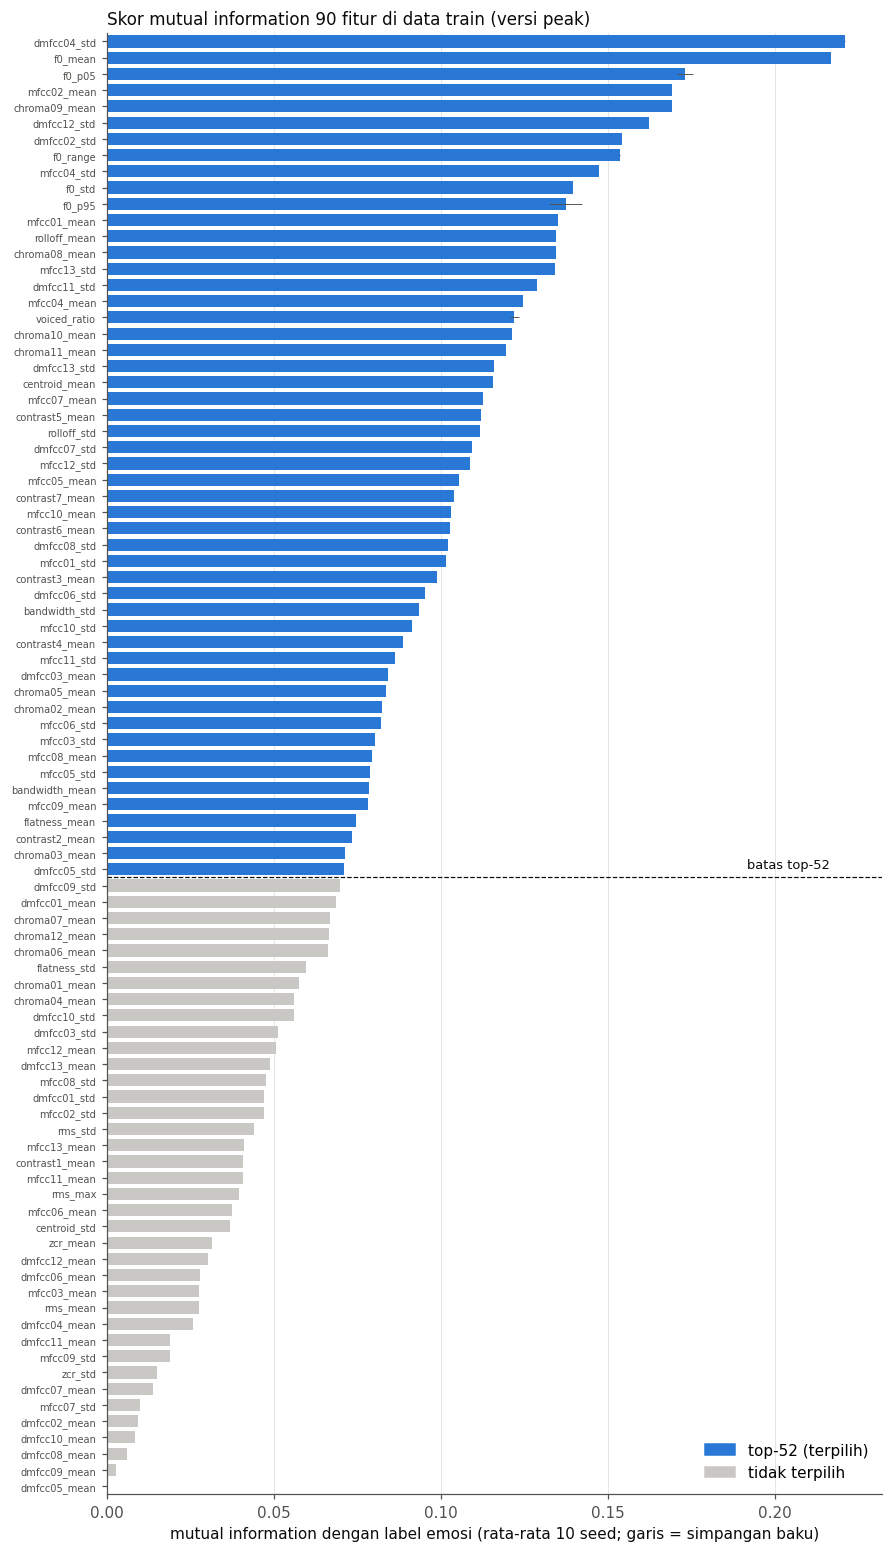

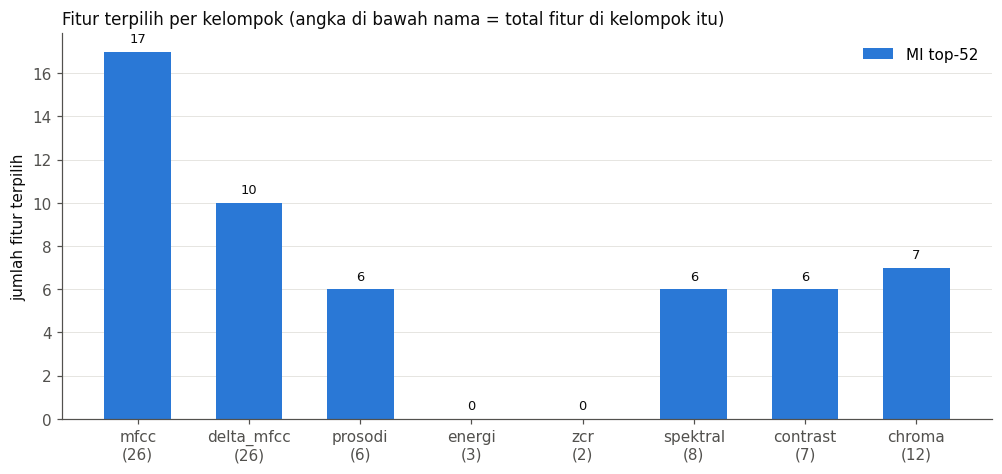

In [7]:
BIRU, ORANYE, ABU = '#2a78d6', '#eb6834', '#c9c8c4'
s = scores.sort_values('rank')
fig, ax = plt.subplots(figsize=(8, 14), layout='constrained')
warna = [BIRU if t else ABU for t in s['in_top_k']]
ax.barh(range(len(s)), s['mi_mean'], xerr=s['mi_std'], color=warna, height=0.75,
        error_kw={'ecolor': '#52514e', 'elinewidth': 0.6, 'capsize': 0})
ax.set_yticks(range(len(s)))
ax.set_yticklabels(s['name'], fontsize=6.5)
ax.set_ylim(len(s) - 0.5, -0.5)
ax.axhline(K - 0.5, color='#0b0b0b', lw=0.8, ls='--')
ax.text(s['mi_mean'].max() * 0.98, K - 0.9, f'batas top-{K}', ha='right', va='bottom', fontsize=8.5, color='#0b0b0b')
ax.set_xlabel('mutual information dengan label emosi (rata-rata 10 seed; garis = simpangan baku)')
ax.grid(axis='x', color='#e4e3df', lw=0.6)
ax.set_axisbelow(True)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=BIRU, label=f'top-{K} (terpilih)'), Patch(color=ABU, label='tidak terpilih')],
          loc='lower right', frameon=False)
ax.set_title(f'Skor mutual information 90 fitur di data train (versi {VERSION})', loc='left', fontsize=11)
fig.savefig(os.path.join(FIG_DIR, 'mi_01_skor_per_fitur.png'))
plt.show()

fig, ax = plt.subplots(figsize=(9, 4.2), layout='constrained')
xg = np.arange(len(grp_order))
w = 0.38 if SA_IDX else 0.6
b1 = ax.bar(xg - (w / 2 if SA_IDX else 0), tab_grp['MI top-k'], width=w, color=BIRU, label=f'MI top-{K}')
bars = [b1]
if SA_IDX:
    b2 = ax.bar(xg + w / 2, tab_grp['SA'], width=w, color=ORANYE, label=f'SA ({len(SA_IDX)} fitur)')
    bars.append(b2)
for bs in bars:
    for r in bs:
        ax.text(r.get_x() + r.get_width() / 2, r.get_height() + 0.3, f'{int(r.get_height())}',
                ha='center', va='bottom', fontsize=8.5, color='#0b0b0b')
ax.set_xticks(xg)
ax.set_xticklabels([f'{g}\n({int(t)})' for g, t in zip(grp_order, tab_grp['total'])])
ax.set_ylabel('jumlah fitur terpilih')
ax.grid(axis='y', color='#e4e3df', lw=0.6)
ax.set_axisbelow(True)
ax.legend(frameon=False, loc='upper right')
ax.set_title('Fitur terpilih per kelompok (angka di bawah nama = total fitur di kelompok itu)', loc='left', fontsize=11)
fig.savefig(os.path.join(FIG_DIR, 'mi_02_kelompok_mi_vs_sa.png'))
plt.show()

## Sel 8 — Ringkasan dan dokumentasi standar

In [8]:
tgl = datetime.now().strftime('%Y-%m-%d')
r_mi = EVAL[EVAL['subset'].str.startswith('MI')].iloc[0]
ringkas = [
    f'Ringkasan mutual information (langkah 10, {tgl})',
    f"config_hash mutual_info: {MI_HASH} | fitur: {CONFIG['features']['config_hash']} | scikit-learn {sklearn.__version__}",
    '',
    f'Data: train split utama (aktor 1-16, {len(tr)} baris), versi {VERSION}, 90 fitur',
    f'Estimator: mutual_info_classif, n_neighbors={N_NEIGHBORS}, rata-rata {len(MI_SEEDS)} seed',
    f'k = {K} ({K_SOURCE})',
    f'Kestabilan top-{K} antar seed: Jaccard min {min(jac_seed):.3f}',
    '',
    '15 fitur MI tertinggi: ' + ', '.join(f"{r.name} ({r.mi_mean:.3f})" for r in scores.head(15).itertuples()),
    'Peringkat fitur energi: ' + ', '.join(f'{F[i]} #{rank[i]}' for i in energi),
    '',
    f'Top-{K} per kelompok: ' + ', '.join(f'{g} {int(n)}/{int(t)}' for g, n, t in zip(grp_order, tab_grp['MI top-k'], tab_grp['total'])),
    f'Top-{K}: {n_cl_mi} kelompok redundan, {dup_mi} fitur kembaran',
] + ([f'SA: ' + ', '.join(f'{g} {int(n)}/{int(t)}' for g, n, t in zip(grp_order, tab_grp['SA'], tab_grp['total'])),
      f'SA: {n_cl_sa} kelompok redundan, {dup_sa} fitur kembaran',
      f'MI vs SA: {len(same)} fitur sama, Jaccard per fitur {J_feat:.3f}, per kelompok {J_clus:.3f}'] if SA_IDX else []) + [
    '',
    'Pratinjau validation (protokol B; angka resmi dari B/C):',
] + [f"  {r['subset']:<16} k={r['k']:<3} val F1 SVM tetap {r['val F1 (SVM tetap)']:.4f} | CV F1 tuning {r['CV F1 train (tuning)']:.4f} | val F1 tuning {r['val F1 (tuning)']:.4f} ({r['parameter terbaik']})"
     for _, r in EVAL.iterrows()] + [
    '',
    f'Verifikasi: {n_ok}/{len(laporan)} OK',
] + ['  ' + x for x in laporan]
teks = '\n'.join(ringkas)
print(teks)
with open(os.path.join(FIG_DIR, 'mi_summary.txt'), 'w', encoding='utf-8') as fh:
    fh.write(teks + '\n')

tabel_eval = '\n'.join(f"| {r['subset']} | {r['k']} | {r['val F1 (SVM tetap)']:.4f} | {r['CV F1 train (tuning)']:.4f} | {r['val F1 (tuning)']:.4f} | {r['parameter terbaik']} |"
                       for _, r in EVAL.iterrows())
readme = f'''# Langkah 10 — Pembanding Filter Method (Mutual Information)

Penanggung jawab: Anggota A · Versi: 1.0 · Dijalankan: {tgl} · config_hash: `{MI_HASH}` (fitur `{CONFIG['features']['config_hash']}`)

## Tujuan

Menyediakan pembanding *filter method* untuk SA: {K} fitur dengan mutual information tertinggi terhadap label emosi, dihitung hanya di data train. Daftar indeks diserahkan ke Anggota B untuk dievaluasi dengan protokol yang sama seperti SA.

## Parameter

| Parameter | Nilai |
| --- | --- |
| Versi tabel fitur | `{VERSION}` (terpilih di baseline Anggota B) |
| k | {K} ({K_SOURCE}) |
| Data | Train split utama, aktor 1–16 ({len(tr)} baris) |
| Estimator | `sklearn.feature_selection.mutual_info_classif`, `n_neighbors={N_NEIGHBORS}`, rata-rata {len(MI_SEEDS)} seed (scikit-learn {sklearn.__version__}) |

## Output

| File | Isi |
| --- | --- |
| `data/analysis/mi_topk_{VERSION}.json` | Daftar {K} indeks dan nama fitur untuk Anggota B (format kontrak `subsets.json`: `run_id`, `method`, `seed`, `lambda`, `partition`, `indices`) |
| `data/analysis/mi_scores_{VERSION}.csv` | Skor MI rata-rata dan simpangan baku, peringkat, status top-k, status di subset SA, nomor kelompok redundan |
| `data/analysis/mi_eval_preview_{VERSION}.csv` | Pratinjau evaluasi validation |
| `figures/mutual_info/` | `mi_01_skor_per_fitur.png`, `mi_02_kelompok_mi_vs_sa.png`, `mi_summary.txt` |

## Hasil

- Top-{K} identik untuk semua seed estimator (Jaccard minimum {min(jac_seed):.3f}).
- Per kelompok: ''' + ', '.join(f'{g} {int(n)}/{int(t)}' for g, n, t in zip(grp_order, tab_grp['MI top-k'], tab_grp['total'])) + f'''.
- Peringkat fitur energi: ''' + ', '.join(f'{F[i]} #{rank[i]}' for i in energi) + f'''.
- Redundansi: top-{K} mencakup {n_cl_mi} kelompok redundan, dengan {dup_mi} fitur kembaran.''' + (f'''
- Dibanding SA ({len(SA_IDX)} fitur, {n_cl_sa} kelompok redundan, {dup_sa} fitur kembaran): {len(same)} fitur sama; Jaccard per fitur {J_feat:.3f}, per kelompok {J_clus:.3f}.''' if SA_IDX else '') + f'''

### Pratinjau evaluasi di validation (protokol Anggota B)

| Subset | k | Val macro F1 (SVM tetap: RBF, C=1, gamma=scale) | CV macro F1 train (tuning) | Val macro F1 (tuning) | Parameter terbaik |
| --- | --- | --- | --- | --- | --- |
{tabel_eval}

Angka resmi untuk paper berasal dari evaluasi Anggota B dan fungsi `evaluate()` Anggota C. Data test tidak dipakai di langkah ini.

## Verifikasi

{n_ok}/{len(laporan)} pemeriksaan OK.

''' + '\n'.join(f'- {x}' for x in laporan) + f'''

## Keterbatasan

- MI menilai setiap fitur sendiri-sendiri, sehingga tidak menangkap fitur yang hanya berguna jika dikombinasikan, dan bisa memilih fitur yang saling redundan.
- Estimator MI berbasis k tetangga terdekat mengandung unsur acak; dirata-ratakan atas {len(MI_SEEDS)} seed.
- k mengikuti subset SA milik B. Jika median k berubah, jalankan ulang dengan nilai `K` yang baru.

## Riwayat versi

| Versi | Tanggal | Perubahan |
| --- | --- | --- |
| 1.0 | {tgl} | Versi pertama |
'''
with open(os.path.join(DOC_DIR, 'README_langkah10_mutual_information.md'), 'w', encoding='utf-8') as fh:
    fh.write(readme)
print('\nTersimpan:', os.path.join(FIG_DIR, 'mi_summary.txt'))
print('Tersimpan:', os.path.join(DOC_DIR, 'README_langkah10_mutual_information.md'))

Ringkasan mutual information (langkah 10, 2026-11-24)
config_hash mutual_info: eccc001f3d | fitur: 0c3114fc78 | scikit-learn 1.6.1

Data: train split utama (aktor 1-16, 960 baris), versi peak, 90 fitur
Estimator: mutual_info_classif, n_neighbors=3, rata-rata 10 seed
k = 52 (SA utama Anggota B (P0, seed 42); median 3 seed SA di P0 = 52 (52, 52, 54))
Kestabilan top-52 antar seed: Jaccard min 1.000

15 fitur MI tertinggi: dmfcc04_std (0.221), f0_mean (0.217), f0_p05 (0.173), mfcc02_mean (0.169), chroma09_mean (0.169), dmfcc12_std (0.162), dmfcc02_std (0.154), f0_range (0.153), mfcc04_std (0.147), f0_std (0.140), f0_p95 (0.137), mfcc01_mean (0.135), rolloff_mean (0.135), chroma08_mean (0.134), mfcc13_std (0.134)
Peringkat fitur energi: rms_mean #79, rms_std #68, rms_max #72

Top-52 per kelompok: mfcc 17/26, delta_mfcc 10/26, prosodi 6/6, energi 0/3, zcr 0/2, spektral 6/8, contrast 6/7, chroma 7/12
Top-52: 39 kelompok redundan, 13 fitur kembaran

Pratinjau validation (protokol B; angka resm

## Selesai — yang dilakukan setelah notebook ini

1. Pastikan Sel 6 menampilkan semua **OK**.
2. Simpan notebook ke `project07/notebooks/Langkah10_AnggotaA_Mutual_Information.ipynb`.
3. Kirim `data/analysis/mi_topk_peak.json` ke Anggota B untuk dievaluasi dengan protokol yang sama dan dicatat di `subsets.json`.
4. Kirim ke saya isi `mi_summary.txt` serta grafik `mi_01` dan `mi_02` untuk Log Kerja.